In [49]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import matplotlib.dates as mdates

In [89]:
money = 1_000_000                   
start = '2015-01-01'               
finish = '2020-12-31'              
stop_loss = 5                     
short_window = 30                  
long_window = 90              

In [90]:
def load_data(ticker, start, finish):
    data = yf.download(ticker, start=start, end=finish)
    data = data[['Open', 'High', 'Low', 'Close']]
    return data

data = load_data(ticker, start, finish)


[*********************100%***********************]  1 of 1 completed


In [ ]:
# Скользящие средние
data['short_ma'] = data['Close'].rolling(window=short_window).mean()
data['long_ma'] = data['Close'].rolling(window=long_window).mean()

In [ ]:
# Сигналы
data['signal'] = 0
data['signal'][short_window:] = np.where(
    (data['short_ma'][short_window:] > data['long_ma'][short_window:]) & 
    (data['short_ma'].shift(1)[short_window:] <= data['long_ma'].shift(1)[short_window:]), 
    1, 0)
data['signal'][short_window:] = np.where(
    (data['short_ma'][short_window:] < data['long_ma'][short_window:]) & 
    (data['short_ma'].shift(1)[short_window:] >= data['long_ma'].shift(1)[short_window:]), 
    -1, data['signal'][short_window:])


/var/folders/wz/7gxs93rj2710v6r1rv_dzzdw0000gn/T/ipykernel_31015/1564333440.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['signal'][short_window:] = np.where(
/var/folders/wz/7gxs93rj2710v6r1rv_dzzdw0000gn/T/ipykernel_31015/1564333440.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['signal'][short_window:] = np.where(


In [ ]:
# Имитация торговли 
def simulate_trading(data, money, stop_loss):
    report = pd.DataFrame(columns=['date', 'signal', 'num_shares', 'share_price', 'share_value', 'cash'])
    
    position = 0
    cash = money
    stop_price = 0
    in_position = False
    
    for i in range(1, len(data)):
        current_date = data.index[i]
        prev_signal = data['signal'].iloc[i-1]
        open_price = data['Open'].iloc[i]
        low_price = data['Low'].iloc[i]
        current_close = data['Close'].iloc[i]
        
        # Проверка стоп-лосса
        if in_position and low_price < stop_price:
            sale_amount = position * stop_price
            cash += sale_amount
            new_row = pd.DataFrame({
                'date': [current_date],
                'signal': ['stop-loss'],
                'num_shares': [0],
                'share_price': [stop_price],
                'share_value': [0],
                'cash': [round(cash, 2)]
            })
            report = pd.concat([report, new_row], ignore_index=True)
            position = 0
            in_position = False
            continue  
        
        # Обработка сигналов
        if prev_signal == 1 and not in_position:
            position = int(cash // open_price)
            if position > 0:
                cash -= position * open_price
                cash = round(cash, 2)
                stop_price = open_price * (1 - stop_loss / 100)
                in_position = True
                
                # Запись сигнала
                new_row = pd.DataFrame({
                    'date': [data.index[i-1]],
                    'signal': ['sig_buy'],
                    'num_shares': [0],
                    'share_price': [data['Close'].iloc[i-1]],
                    'share_value': [0],
                    'cash': [cash]
                })
                report = pd.concat([report, new_row], ignore_index=True)
                
                # Запись покупки
                new_row = pd.DataFrame({
                    'date': [current_date],
                    'signal': ['buy'],
                    'num_shares': [position],
                    'share_price': [open_price],
                    'share_value': [position * open_price],
                    'cash': [cash]
                })
                report = pd.concat([report, new_row], ignore_index=True)
                
        elif prev_signal == -1 and in_position:
            sale_amount = position * open_price
            cash += sale_amount
            cash = round(cash, 2)
            
            # Запись сигнала
            new_row = pd.DataFrame({
                'date': [data.index[i-1]],
                'signal': ['sig_sale'],
                'num_shares': [position],
                'share_price': [data['Close'].iloc[i-1]],
                'share_value': [position * data['Close'].iloc[i-1]],
                'cash': [cash - sale_amount]
            })
            report = pd.concat([report, new_row], ignore_index=True)
            
            # Запись продажи
            new_row = pd.DataFrame({
                'date': [current_date],
                'signal': ['sale'],
                'num_shares': [0],
                'share_price': [open_price],
                'share_value': [0],
                'cash': [cash]
            })
            report = pd.concat([report, new_row], ignore_index=True)
            
            position = 0
            in_position = False
   
    if position > 0:
        new_row = pd.DataFrame({
            'date': [data.index[-1]],
            'signal': ['final'],
            'num_shares': [position],
            'share_price': [data['Close'].iloc[-1]],
            'share_value': [position * data['Close'].iloc[-1]],
            'cash': [cash]
        })
        report = pd.concat([report, new_row], ignore_index=True)
    
    return report

report = simulate_trading(data, money, stop_loss)

In [ ]:
# Итоги
def calculate_results(report):
    if not report.empty:
        last_row = report.iloc[-1]
        final_value = last_row['share_value'] + last_row['cash']
        profit = ((final_value - money) / money) * 100
        print(f"Итоговая стоимость портфеля: {final_value:,.2f}")
        print(f"Прибыль/убыток: {profit:.2f}%")
    else:
        print("Не было совершено ни одной сделки")

calculate_results(report)


Не было совершено ни одной сделки


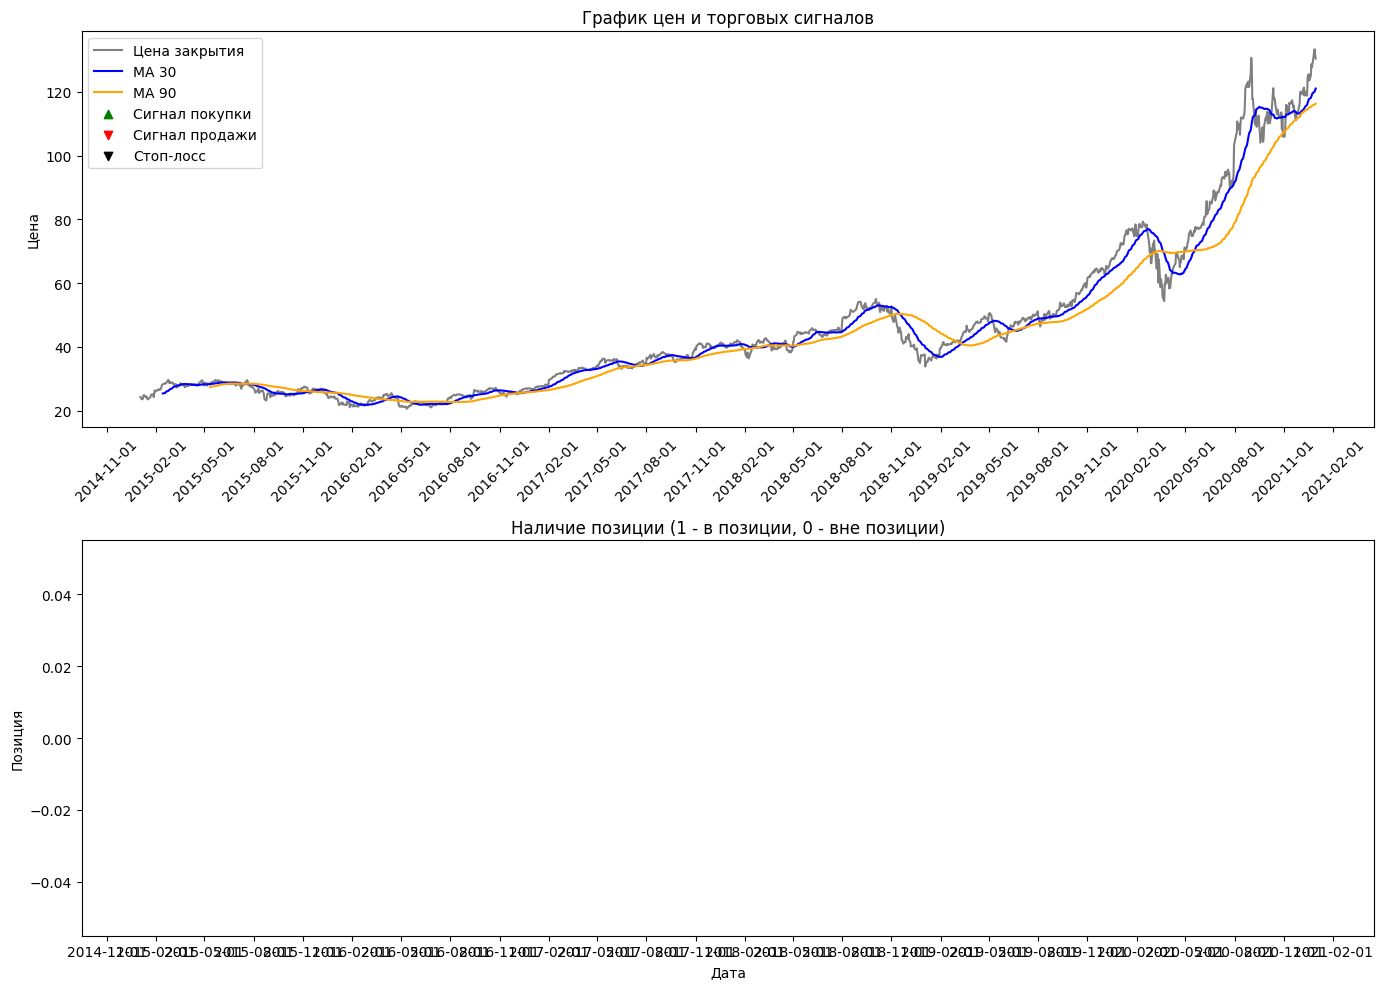

In [ ]:
# Графики
def plot_results(data, report):
    plt.figure(figsize=(14, 10))
    
    # График цен и скользящих средних
    ax1 = plt.subplot(2, 1, 1)
    plt.plot(data.index, data['Close'], label='Цена закрытия', color='black', alpha=0.5)
    plt.plot(data.index, data['short_ma'], label=f'MA {short_window}', color='blue')
    plt.plot(data.index, data['long_ma'], label=f'MA {long_window}', color='orange')
    
    # Отметки сигналов
    buy_signals = report[report['signal'] == 'sig_buy']
    sell_signals = report[report['signal'] == 'sig_sale']
    stop_signals = report[report['signal'] == 'stop-loss']
    
    plt.scatter(buy_signals['date'], 
                data.loc[buy_signals['date'], 'Close'], 
                marker='^', color='g', label='Сигнал покупки')
    plt.scatter(sell_signals['date'], 
                data.loc[sell_signals['date'], 'Close'], 
                marker='v', color='r', label='Сигнал продажи')
    plt.scatter(stop_signals['date'], 
                data.loc[stop_signals['date'], 'Close'], 
                marker='v', color='k', label='Стоп-лосс')
    
    plt.title('График цен и торговых сигналов')
    plt.ylabel('Цена')
    plt.legend()
    
    ax1.xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
    ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.xticks(rotation=45)
    
    # График позиции
    ax2 = plt.subplot(2, 1, 2, sharex=ax1)
    position_data = report.set_index('date')['num_shares']
    plt.plot(position_data.index, (position_data > 0).astype(int), 
             drawstyle='steps-post', label='Позиция')
    plt.title('Наличие позиции (1 - в позиции, 0 - вне позиции)')
    plt.ylabel('Позиция')
    plt.xlabel('Дата')
    
    plt.tight_layout()
    plt.show()

plot_results(data, report)